In [2]:
from pathlib import Path
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

Path("./chest_xray"),


DATASET_ROOT = Path("./chest_xray")
print("Dataset root détecté :", DATASET_ROOT)

Dataset root détecté : chest_xray


In [3]:
classes = ["NORMAL", "PNEUMONIA"]
splits = ["train", "val", "test"]

rows = []

for split in splits:
    for cls in classes:
        folder = DATASET_ROOT / split / cls
        for img_path in folder.glob("*"):
            if img_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                rows.append({
                    "filepath": str(img_path),
                    "label": cls,
                    "original_split": split
                })

df = pd.DataFrame(rows)

print("Nombre total d'images :", len(df))
display(df.head())

print("\nRépartition globale par classe :")
print(df["label"].value_counts())

print("\nRépartition par split d'origine :")
print(df["original_split"].value_counts())

Nombre total d'images : 5856


,filepath,label,original_split
0,chest_xray\train\NORMAL\IM-0115-0001.jpeg,NORMAL,train
1,chest_xray\train\NORMAL\IM-0117-0001.jpeg,NORMAL,train
2,chest_xray\train\NORMAL\IM-0119-0001.jpeg,NORMAL,train
3,chest_xray\train\NORMAL\IM-0122-0001.jpeg,NORMAL,train
4,chest_xray\train\NORMAL\IM-0125-0001.jpeg,NORMAL,train



Répartition globale par classe :
label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Répartition par split d'origine :
original_split
train    5216
test      624
val        16
Name: count, dtype: int64


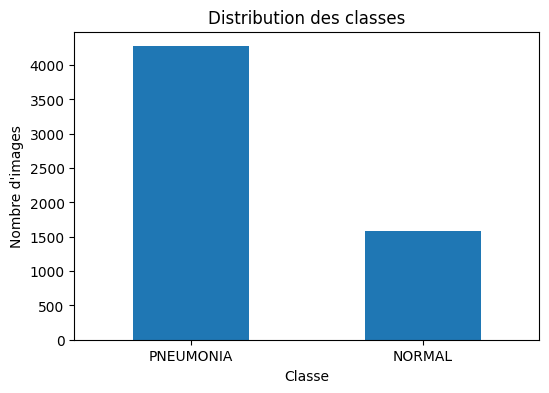

label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64
Ratio de déséquilibre (classe majoritaire / minoritaire) = 2.70


In [4]:
class_counts = df["label"].value_counts()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Distribution des classes")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=0)
plt.show()

print(class_counts)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Ratio de déséquilibre (classe majoritaire / minoritaire) = {imbalance_ratio:.2f}")

In [5]:
#Le dataset est déséquilibré : la classe PNEUMONIA est majoritaire par rapport à la classe NORMAL. 
# Ce déséquilibre risque de biaiser le modèle. Pour le corriger, 
# nous utilisons une pondération des classes (class_weight) calculée sur l’ensemble d’entraînement.

In [6]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomZoom(0.08),
], name="data_augmentation")

print(data_augmentation)

<Sequential name=data_augmentation, built=False>


In [7]:
def preprocess_image(path, label, training=False):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)  
    image = tf.image.resize(image, IMG_SIZE)      
    image = tf.cast(image, tf.float32) / 255.0    

    if training:
        image = data_augmentation(image, training=True)

    return image, tf.cast(label, tf.float32)

In [8]:
# Les images sont redimensionnées en 224×224 pour uniformiser l’entrée et assurer la compatibilité avec VGG16 et ResNet50.
# Les pixels sont normalisés dans [0,1] pour stabiliser l’apprentissage. 
# Une augmentation légère des données est appliquée sur l’ensemble d’entraînement 
# afin d’améliorer la généralisation sans dégrader le réalisme médical des radiographies.

In [9]:
label_map = {"NORMAL": 0, "PNEUMONIA": 1}
df["label_id"] = df["label"].map(label_map)

all_df = df[["filepath", "label", "label_id"]].copy()
display(all_df.head())

,filepath,label,label_id
0,chest_xray\train\NORMAL\IM-0115-0001.jpeg,NORMAL,0
1,chest_xray\train\NORMAL\IM-0117-0001.jpeg,NORMAL,0
2,chest_xray\train\NORMAL\IM-0119-0001.jpeg,NORMAL,0
3,chest_xray\train\NORMAL\IM-0122-0001.jpeg,NORMAL,0
4,chest_xray\train\NORMAL\IM-0125-0001.jpeg,NORMAL,0


In [10]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    all_df,
    test_size=0.30,
    stratify=all_df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Taille train :", len(train_df))
print("Taille val   :", len(val_df))
print("Taille test  :", len(test_df))

Taille train : 4099
Taille val   : 878
Taille test  : 879


In [11]:
print("Répartition TRAIN")
print(train_df["label"].value_counts())
print(train_df["label"].value_counts(normalize=True))

print("\nRépartition VAL")
print(val_df["label"].value_counts())
print(val_df["label"].value_counts(normalize=True))

print("\nRépartition TEST")
print(test_df["label"].value_counts())
print(test_df["label"].value_counts(normalize=True))

Répartition TRAIN
label
PNEUMONIA    2991
NORMAL       1108
Name: count, dtype: int64
label
PNEUMONIA    0.72969
NORMAL       0.27031
Name: proportion, dtype: float64

Répartition VAL
label
PNEUMONIA    641
NORMAL       237
Name: count, dtype: int64
label
PNEUMONIA    0.730068
NORMAL       0.269932
Name: proportion, dtype: float64

Répartition TEST
label
PNEUMONIA    641
NORMAL       238
Name: count, dtype: int64
label
PNEUMONIA    0.729238
NORMAL       0.270762
Name: proportion, dtype: float64


,train,val,test
label,,,
PNEUMONIA,2991,641,641
NORMAL,1108,237,238


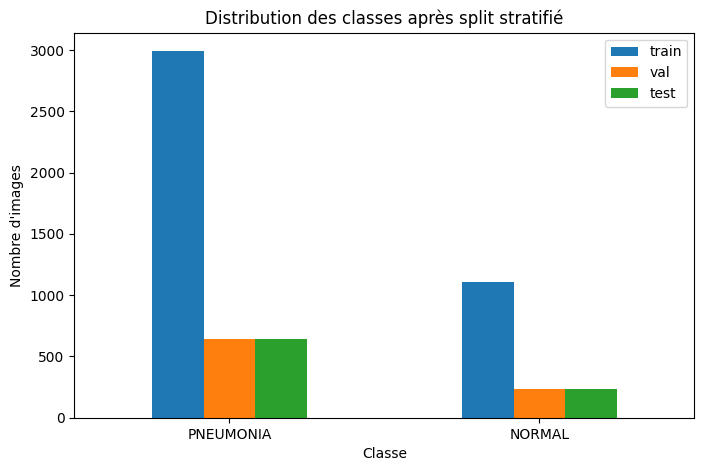

In [12]:
split_stats = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts()
}).fillna(0)

display(split_stats)

split_stats.plot(kind="bar", figsize=(8, 5))
plt.title("Distribution des classes après split stratifié")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=0)
plt.show()

In [13]:
# Les données ont été divisées en trois ensembles selon un split stratifié 70% / 15% / 15%, 
# afin de conserver la proportion des classes dans chaque partition. 
# Ce choix est plus fiable que le split de validation d’origine, qui contenait trop peu d’images.

In [14]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=train_df["label_id"].values
)

class_weight_dict = {
    0: class_weights[0],   # NORMAL
    1: class_weights[1]    # PNEUMONIA
}

print("Poids des classes :", class_weight_dict)

Poids des classes : {0: np.float64(1.8497292418772564), 1: np.float64(0.6852223336676697)}


In [15]:
# Afin de corriger le déséquilibre observé en A.1, nous calculons des poids de classes à partir de l’ensemble d’entraînement.
# La classe minoritaire reçoit un poids plus élevé, ce qui obligera le modèle à accorder davantage d’importance à ses erreurs pendant l’apprentissage.
# Ces poids seront utilisés dans la phase d’entraînement du CNN baseline à l’aide du paramètre class_weight.

In [16]:
def make_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label_id"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(len(dataframe), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(
        lambda x, y: preprocess_image(x, y, training=training),
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

print("train_ds, val_ds et test_ds sont prêts.")

train_ds, val_ds et test_ds sont prêts.


In [17]:
from pathlib import Path

SAVE_DIR = Path("./saved_splits")
SAVE_DIR.mkdir(exist_ok=True)

train_df.to_csv(SAVE_DIR / "train_split.csv", index=False)
val_df.to_csv(SAVE_DIR / "val_split.csv", index=False)
test_df.to_csv(SAVE_DIR / "test_split.csv", index=False)

print("Splits sauvegardés dans", SAVE_DIR)

Splits sauvegardés dans saved_splits


In [18]:
import json

with open(SAVE_DIR / "class_weights.json", "w") as f:
    json.dump({str(k): float(v) for k, v in class_weight_dict.items()}, f, indent=4)

print("Poids des classes sauvegardés.")

config = {
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "classes": ["NORMAL", "PNEUMONIA"]
}

with open(SAVE_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Configuration sauvegardée.")


Poids des classes sauvegardés.
Configuration sauvegardée.


In [19]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [20]:
def build_baseline_cnn(input_shape=(224, 224, 3)):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),

        # Bloc 1
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        # Bloc 2
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        # Classification
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ], name="cnn_baseline")

    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    25,690,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,709,761 (98.07 MB)

 Trainable params: 25,709,761 (98.07 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [22]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

In [23]:
history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


129/129 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.7258 - loss: 0.7480 - precision: 0.8738 - recall: 0.7295 - val_accuracy: 0.8349 - val_loss: 0.4293 - val_precision: 0.9863 - val_recall: 0.7847 - learning_rate: 0.0010
Epoch 2/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - accuracy: 0.8731 - loss: 0.3102 - precision: 0.9491 - recall: 0.8730 - val_accuracy: 0.8827 - val_loss: 0.3125 - val_precision: 0.9838 - val_recall: 0.8534 - learning_rate: 0.0010
Epoch 3/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.8853 - loss: 0.2732 - precision: 0.9539 - recall: 0.8857 - val_accuracy: 0.9317 - val_loss: 0.1978 - val_precision: 0.9786 - val_recall: 0.9267 - learning_rate: 0.0010
Epoch 4/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 208s 1s/step - accuracy: 0.8946 - loss: 0.2601 - precision: 0.9601 - recall: 0.8927 - val_accuracy: 0.9408 - val_loss: 0.1698 - val_precision: 0.9742 - val_recall: 0.9438 - learning_rate: 0.0010
Epoch 5/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.8900

In [25]:
y_true = test_df["label_id"].values
y_prob = baseline_model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)

print(f"Accuracy  : {acc:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")

print("\nRapport de classification :")
print(classification_report(y_true, y_pred, target_names=["NORMAL", "PNEUMONIA"]))

28/28 ━━━━━━━━━━━━━━━━━━━━ 6s 199ms/step
Accuracy  : 0.9317
F1-score  : 0.9528
Precision : 0.9604
Recall    : 0.9454

Rapport de classification :
              precision    recall  f1-score   support

      NORMAL       0.86      0.89      0.88       238
   PNEUMONIA       0.96      0.95      0.95       641

    accuracy                           0.93       879
   macro avg       0.91      0.92      0.91       879
weighted avg       0.93      0.93      0.93       879



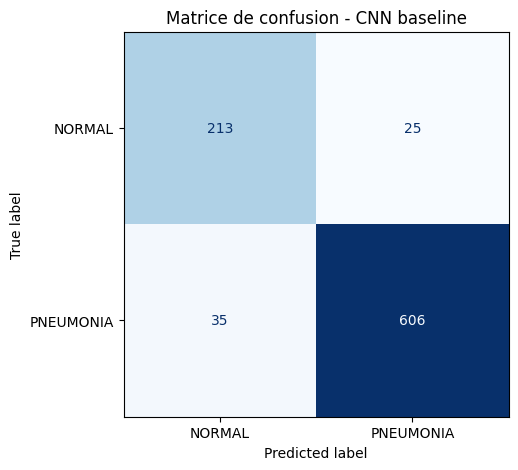

In [26]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Matrice de confusion - CNN baseline")
plt.show()

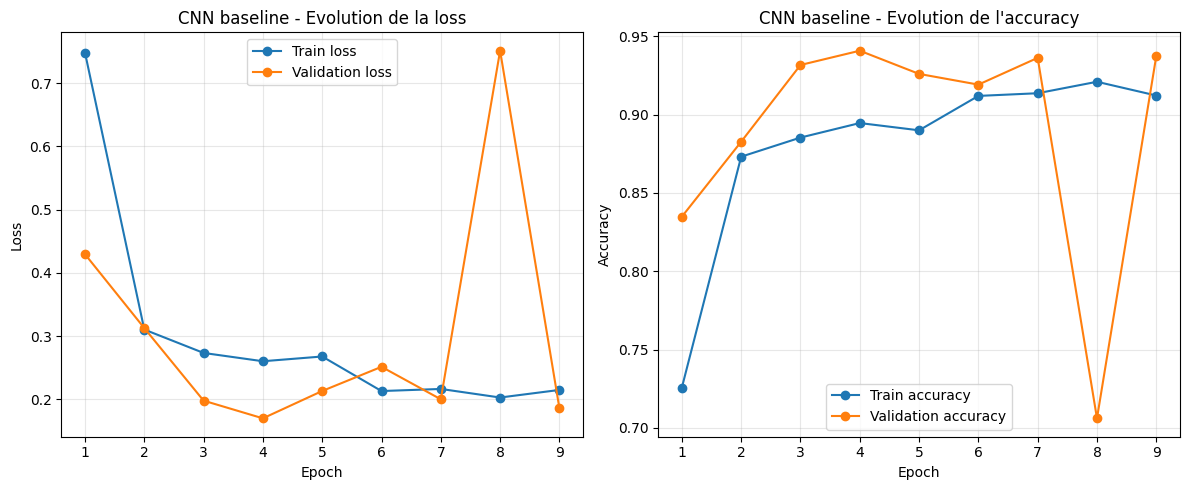

In [27]:
import matplotlib.pyplot as plt
import numpy as np

def plot_training_history(history, model_name="CNN baseline"):
    hist = history.history
    epochs = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(12, 5))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, hist["loss"], marker="o", label="Train loss")
    plt.plot(epochs, hist["val_loss"], marker="o", label="Validation loss")
    plt.title(f"{model_name} - Evolution de la loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, hist["accuracy"], marker="o", label="Train accuracy")
    plt.plot(epochs, hist["val_accuracy"], marker="o", label="Validation accuracy")
    plt.title(f"{model_name} - Evolution de l'accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_history(history_baseline, model_name="CNN baseline")

In [28]:
best_epoch = np.argmin(history_baseline.history["val_loss"]) + 1
print("Meilleure époque selon la validation loss :", best_epoch)

Meilleure époque selon la validation loss : 4


In [ ]:
# Les courbes d’apprentissage montrent un apprentissage correct du CNN baseline,
#  sans sous-apprentissage. La meilleure généralisation est obtenue vers l’époque 4,
#  où la validation loss est minimale. Après cette étape,
#  les performances de validation deviennent plus instables,
#  ce qui suggère un léger début de surapprentissage ou une instabilité ponctuelle de l’optimisation,
#  sans dégradation durable.

In [29]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess

In [30]:
class TimeHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.time() - self.start_time)

In [31]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
SEED = 42

In [32]:
data_augmentation_pretrained = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomZoom(0.08),
], name="data_augmentation_pretrained")

In [33]:
def load_image_raw(path, label, training=False):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)   # on garde l’échelle 0-255

    if training:
        image = data_augmentation_pretrained(image, training=True)

    return image, tf.cast(label, tf.float32)

In [34]:
def make_pretrained_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label_id"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(len(dataframe), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(
        lambda x, y: load_image_raw(x, y, training=training),
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

In [35]:
train_ds_pre = make_pretrained_dataset(train_df, training=True)
val_ds_pre   = make_pretrained_dataset(val_df, training=False)
test_ds_pre  = make_pretrained_dataset(test_df, training=False)

print("Datasets pour modèles préentraînés prêts.")

Datasets pour modèles préentraînés prêts.


In [36]:
def evaluate_model(model, test_ds, test_df, model_name="model"):
    y_true = test_df["label_id"].values
    y_prob = model.predict(test_ds).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)

    print(f"\n=== {model_name} ===")
    print(f"Accuracy  : {acc:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print("\nRapport de classification :")
    print(classification_report(y_true, y_pred, target_names=["NORMAL", "PNEUMONIA"]))

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["NORMAL", "PNEUMONIA"])
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    plt.title(f"Matrice de confusion - {model_name}")
    plt.show()

    return {
        "Architecture": model_name,
        "Accuracy": acc,
        "F1-score": f1,
        "Precision": prec,
        "Recall": rec
    }

In [37]:
def plot_history(history, title="Model"):
    hist = history.history
    epochs = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, hist["loss"], marker="o", label="Train loss")
    plt.plot(epochs, hist["val_loss"], marker="o", label="Validation loss")
    plt.title(f"{title} - Evolution de la loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, hist["accuracy"], marker="o", label="Train accuracy")
    plt.plot(epochs, hist["val_accuracy"], marker="o", label="Validation accuracy")
    plt.title(f"{title} - Evolution de l'accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [38]:
def build_vgg16_frozen(input_shape=(224, 224, 3)):
    base_model = VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )
    base_model.trainable = False

    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.Lambda(vgg16_preprocess)(inputs)
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs, name="VGG16_frozen")
    return model, base_model

In [39]:
vgg16_frozen, vgg16_base = build_vgg16_frozen()
vgg16_frozen.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 25s 0us/step



Model: "VGG16_frozen"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [40]:
vgg16_frozen.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [41]:
vgg16_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

vgg16_time_frozen = TimeHistory()

history_vgg16_frozen = vgg16_frozen.fit(
    train_ds_pre,
    validation_data=val_ds_pre,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=vgg16_callbacks + [vgg16_time_frozen],
    verbose=1
)

Epoch 1/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 937s 7s/step - accuracy: 0.8553 - loss: 0.4319 - precision: 0.9398 - recall: 0.8566 - val_accuracy: 0.8850 - val_loss: 0.2817 - val_precision: 0.9874 - val_recall: 0.8534 - learning_rate: 0.0010
Epoch 2/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 928s 7s/step - accuracy: 0.9256 - loss: 0.2029 - precision: 0.9736 - recall: 0.9231 - val_accuracy: 0.9169 - val_loss: 0.2142 - val_precision: 0.9846 - val_recall: 0.9002 - learning_rate: 0.0010
Epoch 3/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 1265s 10s/step - accuracy: 0.9334 - loss: 0.1811 - precision: 0.9752 - recall: 0.9325 - val_accuracy: 0.9226 - val_loss: 0.2107 - val_precision: 0.9897 - val_recall: 0.9033 - learning_rate: 0.0010
Epoch 4/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 1362s 10s/step - accuracy: 0.9351 - loss: 0.1682 - precision: 0.9749 - recall: 0.9351 - val_accuracy: 0.9248 - val_loss: 0.1889 - val_precision: 0.9848 - val_recall: 0.9111 - learning_rate: 0.0010
Epoch 5/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 1437s 11s/step -

KeyboardInterrupt: 

In [42]:
plot_history(history_vgg16_frozen, "VGG16 frozen")

NameError: name 'history_vgg16_frozen' is not defined

28/28 ━━━━━━━━━━━━━━━━━━━━ 252s 9s/step

=== VGG16 frozen ===
Accuracy  : 0.9329
F1-score  : 0.9526
Precision : 0.9818
Recall    : 0.9251

Rapport de classification :
              precision    recall  f1-score   support

      NORMAL       0.83      0.95      0.88       238
   PNEUMONIA       0.98      0.93      0.95       641

    accuracy                           0.93       879
   macro avg       0.90      0.94      0.92       879
weighted avg       0.94      0.93      0.93       879



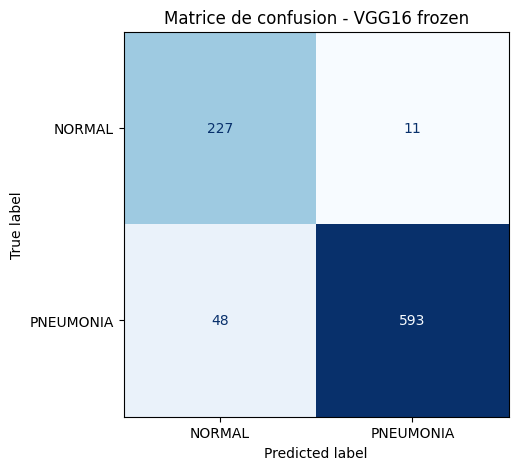

Temps moyen/époque : 1185.9050394058227


In [43]:
vgg16_frozen_results = evaluate_model(
    vgg16_frozen,
    test_ds_pre,
    test_df,
    model_name="VGG16 frozen"
)

print("Temps moyen/époque :", np.mean(vgg16_time_frozen.epoch_times))

In [45]:
vgg16_base.trainable = True

for layer in vgg16_base.layers[:-4]:
    layer.trainable = False

for layer in vgg16_base.layers[-4:]:
    layer.trainable = True

In [46]:
vgg16_frozen.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [47]:
vgg16_time_ft = TimeHistory()

history_vgg16_ft = vgg16_frozen.fit(
    train_ds_pre,
    validation_data=val_ds_pre,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=vgg16_callbacks + [vgg16_time_ft],
    verbose=1
)

Epoch 1/10
  1/129 ━━━━━━━━━━━━━━━━━━━━ 29:33 14s/step - accuracy: 1.0000 - loss: 0.0391 - precision: 1.0000 - recall: 1.0000

KeyboardInterrupt: 

In [ ]:
plot_history(history_vgg16_ft, "VGG16 fine-tuning")

In [ ]:
vgg16_ft_results = evaluate_model(
    vgg16_frozen,
    test_ds_pre,
    test_df,
    model_name="VGG16 fine-tuned"
)

print("Temps moyen/époque :", np.mean(vgg16_time_ft.epoch_times))

In [ ]:
def build_resnet50_frozen(input_shape=(224, 224, 3)):
    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )
    base_model.trainable = False

    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.Lambda(resnet50_preprocess)(inputs)
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs, name="ResNet50_frozen")
    return model, base_model

In [ ]:
resnet50_frozen, resnet50_base = build_resnet50_frozen()
resnet50_frozen.summary()

In [ ]:
resnet50_frozen.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [ ]:
resnet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

resnet50_time_frozen = TimeHistory()

history_resnet50_frozen = resnet50_frozen.fit(
    train_ds_pre,
    validation_data=val_ds_pre,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=resnet_callbacks + [resnet50_time_frozen],
    verbose=1
)

In [ ]:
plot_history(history_resnet50_frozen, "ResNet50 frozen")

In [ ]:
resnet50_frozen_results = evaluate_model(
    resnet50_frozen,
    test_ds_pre,
    test_df,
    model_name="ResNet50 frozen"
)

print("Temps moyen/époque :", np.mean(resnet50_time_frozen.epoch_times))

In [ ]:
resnet50_base.trainable = True

for layer in resnet50_base.layers[:-10]:
    layer.trainable = False

for layer in resnet50_base.layers[-10:]:
    layer.trainable = True

In [ ]:
for layer in resnet50_base.layers[-15:]:
    print(layer.name, layer.trainable)

In [ ]:
resnet50_frozen.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [ ]:
resnet50_time_ft = TimeHistory()

history_resnet50_ft = resnet50_frozen.fit(
    train_ds_pre,
    validation_data=val_ds_pre,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=resnet_callbacks + [resnet50_time_ft],
    verbose=1
)

In [ ]:
plot_history(history_resnet50_ft, "ResNet50 fine-tuning")

In [ ]:
resnet50_ft_results = evaluate_model(
    resnet50_frozen,
    test_ds_pre,
    test_df,
    model_name="ResNet50 fine-tuned"
)

print("Temps moyen/époque :", np.mean(resnet50_time_ft.epoch_times))

In [ ]:
all_results = [
    baseline_results,
    vgg16_frozen_results,
    vgg16_ft_results,
    resnet50_frozen_results,
    resnet50_ft_results
]

results_df = pd.DataFrame(all_results)
results_df

In [ ]:
##########################

#        PARTIE B        #

##########################

In [50]:
import os
import time
import glob
import math
import random
import xml.etree.ElementTree as ET
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torchvision
from torchvision import transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights

from ultralytics import YOLO

In [51]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

Device: cpu
Torch: 2.10.0+cpu
Torchvision: 0.25.0+cpu


In [54]:
# Dossier d'images pour la partie B
IMAGE_DIR = Path("./chest_xray/test/PNEUMONIA")

# Dossier XML LabelImg (optionnel)
ANNOT_DIR = Path("./annotations_xml")

# Extensions autorisées
IMG_EXTS = [".jpg", ".jpeg", ".png"]

image_paths = []
for ext in IMG_EXTS:
    image_paths.extend(IMAGE_DIR.glob(f"*{ext}"))

image_paths = sorted(image_paths)
print("Nombre d'images trouvées :", len(image_paths))
image_paths[:5]

Nombre d'images trouvées : 390


[WindowsPath('chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg'),
 WindowsPath('chest_xray/test/PNEUMONIA/person100_bacteria_477.jpeg'),
 WindowsPath('chest_xray/test/PNEUMONIA/person100_bacteria_478.jpeg'),
 WindowsPath('chest_xray/test/PNEUMONIA/person100_bacteria_479.jpeg'),
 WindowsPath('chest_xray/test/PNEUMONIA/person100_bacteria_480.jpeg')]

In [55]:
def compute_iou(boxA, boxB):
    """
    box format: [xmin, ymin, xmax, ymax]
    """
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    inter_w = max(0, xB - xA)
    inter_h = max(0, yB - yA)
    inter_area = inter_w * inter_h

    areaA = max(0, boxA[2] - boxA[0]) * max(0, boxA[3] - boxA[1])
    areaB = max(0, boxB[2] - boxB[0]) * max(0, boxB[3] - boxB[1])

    union = areaA + areaB - inter_area

    if union == 0:
        return 0.0

    return inter_area / union

In [56]:
box1 = [50, 50, 150, 150]
box2 = [100, 100, 200, 200]

iou_test = compute_iou(box1, box2)
print("IoU test =", round(iou_test, 4))

IoU test = 0.1429


In [57]:
def draw_boxes_on_image(image, boxes, colors=None, labels=None, thickness=2):
    img = image.copy()

    if colors is None:
        colors = [(0, 255, 0)] * len(boxes)

    if labels is None:
        labels = [""] * len(boxes)

    for box, color, label in zip(boxes, colors, labels):
        x1, y1, x2, y2 = map(int, box)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, thickness)

        if label:
            cv2.putText(
                img,
                label,
                (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                color,
                2,
                cv2.LINE_AA
            )
    return img

In [58]:
def show_iou_example(image_path, boxA, boxB, title=None):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    iou = compute_iou(boxA, boxB)

    vis = draw_boxes_on_image(
        image,
        boxes=[boxA, boxB],
        colors=[(255, 0, 0), (0, 255, 0)],
        labels=["Box A", "Box B"]
    )

    plt.figure(figsize=(7, 7))
    plt.imshow(vis)
    plt.title(title if title else f"IoU = {iou:.4f}")
    plt.axis("off")
    plt.show()

    return iou

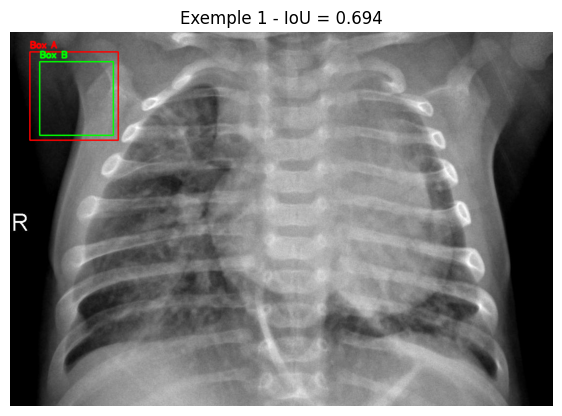

Exemple 1 -> IoU = 0.6944


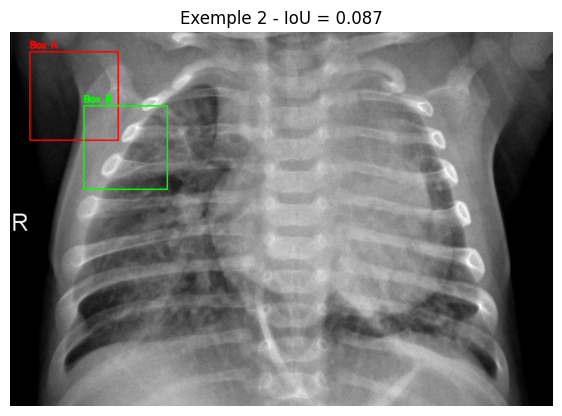

Exemple 2 -> IoU = 0.0869


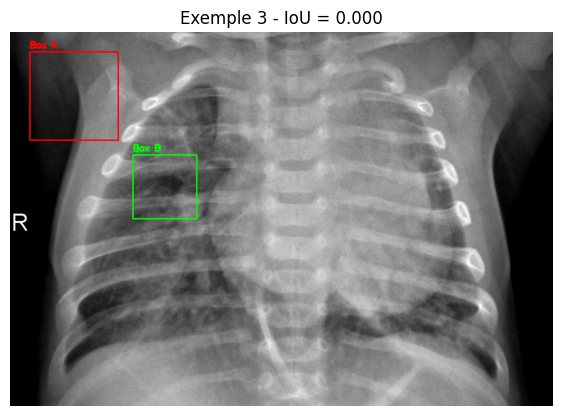

Exemple 3 -> IoU = 0.0000


In [59]:
if len(image_paths) > 0:
    sample_img = image_paths[0]

    example_boxes = [
        ([40, 40, 220, 220], [60, 60, 210, 210]),   # IoU élevé
        ([40, 40, 220, 220], [150, 150, 320, 320]), # IoU moyen
        ([40, 40, 220, 220], [250, 250, 380, 380])  # IoU faible
    ]

    for i, (b1, b2) in enumerate(example_boxes, start=1):
        iou = show_iou_example(sample_img, b1, b2, title=f"Exemple {i} - IoU = {compute_iou(b1,b2):.3f}")
        print(f"Exemple {i} -> IoU = {iou:.4f}")

In [60]:
iou_threshold_tp = 0.5
print("Seuil expérimental retenu pour considérer une détection correcte :", iou_threshold_tp)

Seuil expérimental retenu pour considérer une détection correcte : 0.5


In [61]:
def non_max_suppression(boxes, scores, iou_threshold=0.5):
    """
    boxes: list or np.array of shape (N, 4)
    scores: list or np.array of shape (N,)
    returns: indices kept
    """
    if len(boxes) == 0:
        return []

    boxes = np.array(boxes, dtype=np.float32)
    scores = np.array(scores, dtype=np.float32)

    x1 = boxes[:, 0]
    y1 = boxes[:, 1]
    x2 = boxes[:, 2]
    y2 = boxes[:, 3]

    areas = (x2 - x1) * (y2 - y1)
    order = scores.argsort()[::-1]

    keep = []

    while order.size > 0:
        i = order[0]
        keep.append(i)

        xx1 = np.maximum(x1[i], x1[order[1:]])
        yy1 = np.maximum(y1[i], y1[order[1:]])
        xx2 = np.minimum(x2[i], x2[order[1:]])
        yy2 = np.minimum(y2[i], y2[order[1:]])

        w = np.maximum(0.0, xx2 - xx1)
        h = np.maximum(0.0, yy2 - yy1)
        inter = w * h

        union = areas[i] + areas[order[1:]] - inter
        ious = np.zeros_like(inter)
        valid = union > 0
        ious[valid] = inter[valid] / union[valid]

        inds = np.where(ious < iou_threshold)[0]
        order = order[inds + 1]

    return keep

In [62]:
candidate_boxes = [
    [50, 50, 200, 200],
    [60, 60, 210, 210],
    [250, 60, 380, 220],
    [255, 70, 375, 215]
]

candidate_scores = [0.95, 0.88, 0.90, 0.70]

kept_indices = non_max_suppression(candidate_boxes, candidate_scores, iou_threshold=0.5)
print("Indices conservés :", kept_indices)
print("Boîtes conservées :", [candidate_boxes[i] for i in kept_indices])

Indices conservés : [np.int64(0), np.int64(2)]
Boîtes conservées : [[50, 50, 200, 200], [250, 60, 380, 220]]


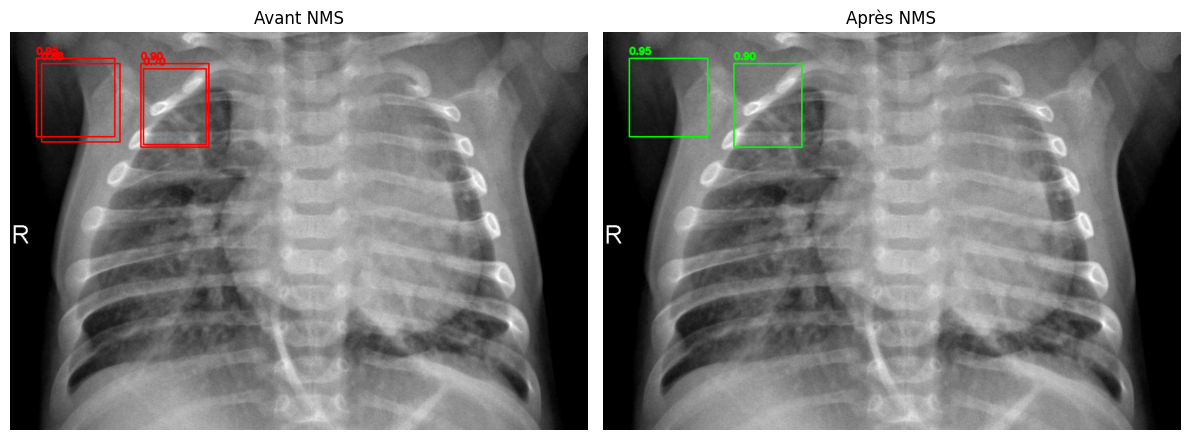

In [63]:
if len(image_paths) > 0:
    image = cv2.imread(str(image_paths[0]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    before = draw_boxes_on_image(
        image,
        candidate_boxes,
        colors=[(255, 0, 0)] * len(candidate_boxes),
        labels=[f"{s:.2f}" for s in candidate_scores]
    )

    after_boxes = [candidate_boxes[i] for i in kept_indices]
    after_scores = [candidate_scores[i] for i in kept_indices]

    after = draw_boxes_on_image(
        image,
        after_boxes,
        colors=[(0, 255, 0)] * len(after_boxes),
        labels=[f"{s:.2f}" for s in after_scores]
    )

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(before)
    plt.title("Avant NMS")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(after)
    plt.title("Après NMS")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [64]:
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
faster_model = fasterrcnn_resnet50_fpn(weights=weights)
faster_model = faster_model.to(DEVICE)
faster_model.eval()

to_tensor = transforms.ToTensor()

print("Faster R-CNN chargé.")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\falaq/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [01:09<00:00, 2.41MB/s] 


Faster R-CNN chargé.


In [65]:
COCO_INSTANCE_CATEGORY_NAMES = weights.meta["categories"]
len(COCO_INSTANCE_CATEGORY_NAMES), COCO_INSTANCE_CATEGORY_NAMES[:10]

(91,
 ['__background__',
  'person',
  'bicycle',
  'car',
  'motorcycle',
  'airplane',
  'bus',
  'train',
  'truck',
  'boat'])

In [66]:
@torch.no_grad()
def faster_predict(image_path, model, score_threshold=0.5):
    image = Image.open(image_path).convert("RGB")
    image_tensor = to_tensor(image).to(DEVICE)

    outputs = model([image_tensor])[0]

    boxes = outputs["boxes"].detach().cpu().numpy()
    scores = outputs["scores"].detach().cpu().numpy()
    labels = outputs["labels"].detach().cpu().numpy()

    keep = scores >= score_threshold

    boxes = boxes[keep]
    scores = scores[keep]
    labels = labels[keep]

    return np.array(image), boxes, scores, labels

In [67]:
def show_faster_predictions(image_path, model, score_threshold=0.5, max_det=10):
    image, boxes, scores, labels = faster_predict(image_path, model, score_threshold)

    boxes = boxes[:max_det]
    scores = scores[:max_det]
    labels = labels[:max_det]

    vis_boxes = []
    vis_labels = []

    for box, score, label in zip(boxes, scores, labels):
        class_name = COCO_INSTANCE_CATEGORY_NAMES[int(label)]
        vis_boxes.append(box.tolist())
        vis_labels.append(f"{class_name} {score:.2f}")

    vis = draw_boxes_on_image(
        image,
        vis_boxes,
        colors=[(255, 0, 0)] * len(vis_boxes),
        labels=vis_labels
    )

    plt.figure(figsize=(8, 8))
    plt.imshow(vis)
    plt.title(f"Faster R-CNN - seuil={score_threshold}")
    plt.axis("off")
    plt.show()

    return boxes, scores, labels

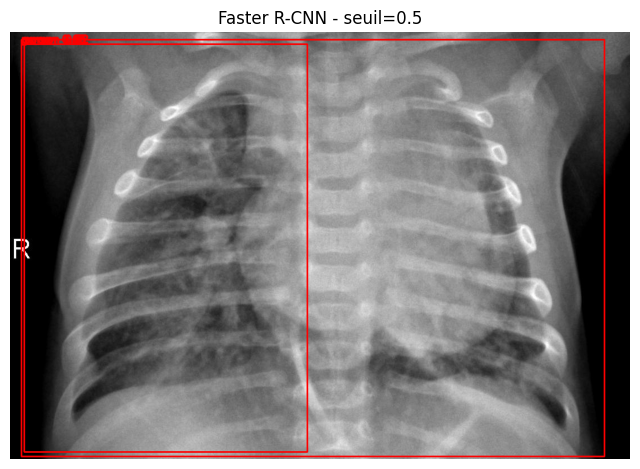

In [68]:
if len(image_paths) > 0:
    show_faster_predictions(image_paths[0], faster_model, score_threshold=0.5)

In [69]:
def count_detections_faster(image_paths, model, thresholds=[0.3, 0.5, 0.7]):
    rows = []

    for thr in thresholds:
        det_counts = []
        mean_scores = []

        for p in image_paths:
            _, boxes, scores, labels = faster_predict(p, model, score_threshold=thr)
            det_counts.append(len(boxes))
            mean_scores.append(float(scores.mean()) if len(scores) > 0 else 0.0)

        rows.append({
            "threshold": thr,
            "avg_num_detections": np.mean(det_counts),
            "avg_score": np.mean(mean_scores)
        })

    return pd.DataFrame(rows)

In [70]:
faster_threshold_df = count_detections_faster(image_paths[:20], faster_model, thresholds=[0.3, 0.5, 0.7, 0.8])
faster_threshold_df

,threshold,avg_num_detections,avg_score
0,0.3,2.90,0.606264
1,0.5,1.75,0.739749
2,0.7,0.85,0.592868
3,0.8,0.70,0.479061


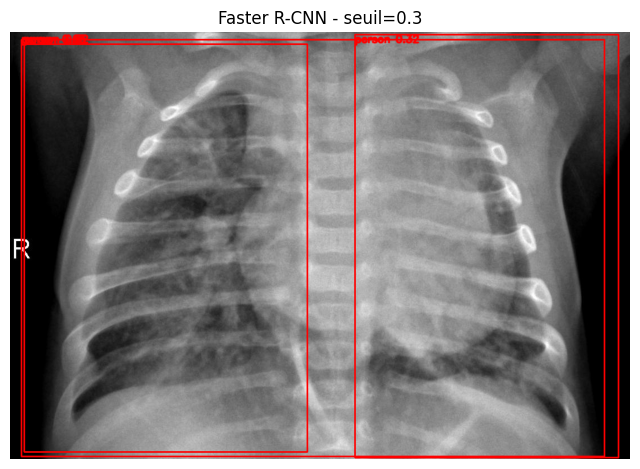

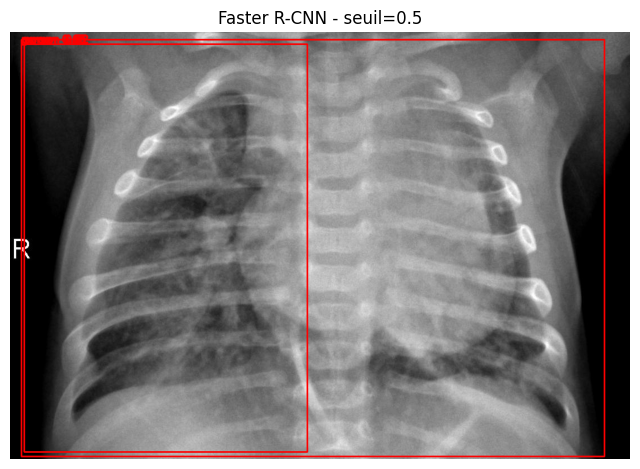

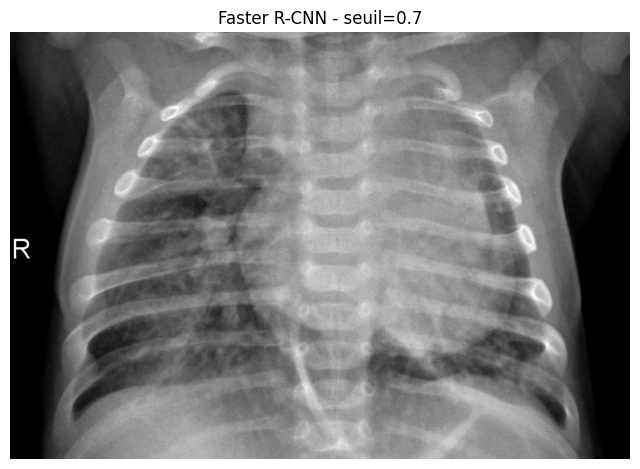

In [71]:
if len(image_paths) > 0:
    test_img = image_paths[0]
    for thr in [0.3, 0.5, 0.7]:
        show_faster_predictions(test_img, faster_model, score_threshold=thr)

In [72]:
@torch.no_grad()
def benchmark_faster(image_paths, model, score_threshold=0.5, warmup=3):
    paths = image_paths[:20]

    # warmup
    for p in paths[:warmup]:
        image = Image.open(p).convert("RGB")
        image_tensor = to_tensor(image).to(DEVICE)
        _ = model([image_tensor])

    times_ms = []

    for p in paths:
        image = Image.open(p).convert("RGB")
        image_tensor = to_tensor(image).to(DEVICE)

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()
        _ = model([image_tensor])

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        end = time.perf_counter()
        times_ms.append((end - start) * 1000)

    return np.mean(times_ms), np.std(times_ms), times_ms

In [73]:
faster_mean_ms, faster_std_ms, faster_times = benchmark_faster(image_paths, faster_model)
print(f"Faster R-CNN - temps moyen: {faster_mean_ms:.2f} ms ± {faster_std_ms:.2f}")

Faster R-CNN - temps moyen: 5881.02 ms ± 899.09


In [74]:
yolo_model = YOLO("yolov8n.pt")
print("YOLOv8n chargé.")

YOLOv8n chargé.


In [75]:
def yolo_predict(image_path, model, conf_threshold=0.25):
    results = model(str(image_path), conf=conf_threshold, verbose=False)
    r = results[0]

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    boxes = []
    scores = []
    labels = []

    if r.boxes is not None and len(r.boxes) > 0:
        xyxy = r.boxes.xyxy.cpu().numpy()
        conf = r.boxes.conf.cpu().numpy()
        cls = r.boxes.cls.cpu().numpy().astype(int)

        boxes = xyxy
        scores = conf
        labels = cls

    return image, boxes, scores, labels, results

In [76]:
def show_yolo_predictions(image_path, model, conf_threshold=0.25, max_det=10):
    image, boxes, scores, labels, results = yolo_predict(image_path, model, conf_threshold)

    vis_boxes = []
    vis_labels = []

    for box, score, label in zip(boxes[:max_det], scores[:max_det], labels[:max_det]):
        class_name = model.names[int(label)]
        vis_boxes.append(box.tolist())
        vis_labels.append(f"{class_name} {score:.2f}")

    vis = draw_boxes_on_image(
        image,
        vis_boxes,
        colors=[(0, 255, 0)] * len(vis_boxes),
        labels=vis_labels
    )

    plt.figure(figsize=(8, 8))
    plt.imshow(vis)
    plt.title(f"YOLOv8n - conf={conf_threshold}")
    plt.axis("off")
    plt.show()

    return boxes, scores, labels

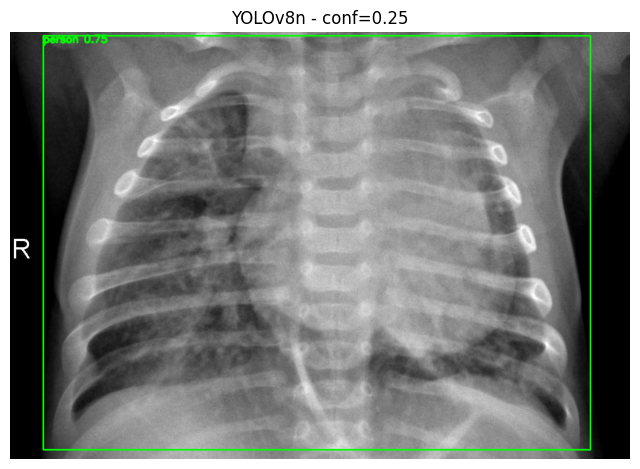

In [77]:
if len(image_paths) > 0:
    show_yolo_predictions(image_paths[0], yolo_model, conf_threshold=0.25)

In [78]:
def benchmark_yolo(image_paths, model, conf_threshold=0.25, warmup=3):
    paths = image_paths[:20]

    for p in paths[:warmup]:
        _ = model(str(p), conf=conf_threshold, verbose=False)

    times_ms = []

    for p in paths:
        start = time.perf_counter()
        _ = model(str(p), conf=conf_threshold, verbose=False)
        end = time.perf_counter()
        times_ms.append((end - start) * 1000)

    return np.mean(times_ms), np.std(times_ms), times_ms

In [79]:
yolo_mean_ms, yolo_std_ms, yolo_times = benchmark_yolo(image_paths, yolo_model, conf_threshold=0.25)
print(f"YOLOv8n - temps moyen: {yolo_mean_ms:.2f} ms ± {yolo_std_ms:.2f}")

YOLOv8n - temps moyen: 242.88 ms ± 49.60


In [80]:
def summarize_detector(image_paths, detector_name, model, threshold):
    num_dets = []
    mean_scores = []

    for p in image_paths[:20]:
        if detector_name == "faster":
            _, boxes, scores, labels = faster_predict(p, model, score_threshold=threshold)
        elif detector_name == "yolo":
            _, boxes, scores, labels, _ = yolo_predict(p, model, conf_threshold=threshold)
        else:
            raise ValueError("detector_name must be 'faster' or 'yolo'")

        num_dets.append(len(boxes))
        mean_scores.append(float(np.mean(scores)) if len(scores) > 0 else 0.0)

    return np.mean(num_dets), np.mean(mean_scores)

In [81]:
faster_avg_det, faster_avg_score = summarize_detector(image_paths, "faster", faster_model, 0.5)
yolo_avg_det, yolo_avg_score = summarize_detector(image_paths, "yolo", yolo_model, 0.25)

print("Faster R-CNN -> nb detections moy:", round(faster_avg_det, 2), "| score moyen:", round(faster_avg_score, 3))
print("YOLOv8n      -> nb detections moy:", round(yolo_avg_det, 2), "| score moyen:", round(yolo_avg_score, 3))

Faster R-CNN -> nb detections moy: 1.75 | score moyen: 0.74
YOLOv8n      -> nb detections moy: 1.25 | score moyen: 0.534


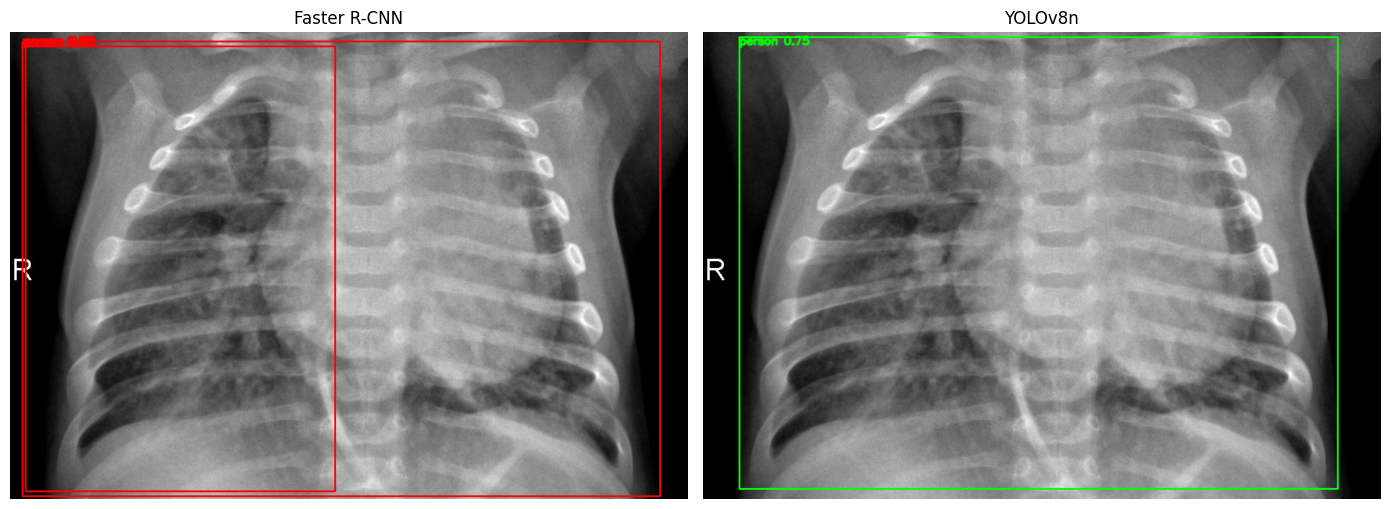

In [82]:
if len(image_paths) > 0:
    test_img = image_paths[0]

    image_f, boxes_f, scores_f, labels_f = faster_predict(test_img, faster_model, score_threshold=0.5)
    vis_f = draw_boxes_on_image(
        image_f,
        [b.tolist() for b in boxes_f[:10]],
        colors=[(255, 0, 0)] * min(10, len(boxes_f)),
        labels=[f"{COCO_INSTANCE_CATEGORY_NAMES[int(l)]} {s:.2f}" for l, s in zip(labels_f[:10], scores_f[:10])]
    )

    image_y, boxes_y, scores_y, labels_y, _ = yolo_predict(test_img, yolo_model, conf_threshold=0.25)
    vis_y = draw_boxes_on_image(
        image_y,
        [b.tolist() for b in boxes_y[:10]],
        colors=[(0, 255, 0)] * min(10, len(boxes_y)),
        labels=[f"{yolo_model.names[int(l)]} {s:.2f}" for l, s in zip(labels_y[:10], scores_y[:10])]
    )

    plt.figure(figsize=(14, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(vis_f)
    plt.title("Faster R-CNN")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(vis_y)
    plt.title("YOLOv8n")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [83]:
comparison_B = pd.DataFrame([
    {
        "Critere": "Temps inference (ms)",
        "Faster R-CNN": round(faster_mean_ms, 2),
        "YOLO v8n": round(yolo_mean_ms, 2),
        "Meilleur": "YOLO v8n" if yolo_mean_ms < faster_mean_ms else "Faster R-CNN"
    },
    {
        "Critere": "Nb. detections moy.",
        "Faster R-CNN": round(faster_avg_det, 2),
        "YOLO v8n": round(yolo_avg_det, 2),
        "Meilleur": "A discuter"
    },
    {
        "Critere": "Score confiance moy.",
        "Faster R-CNN": round(faster_avg_score, 3),
        "YOLO v8n": round(yolo_avg_score, 3),
        "Meilleur": "A discuter"
    },
    {
        "Critere": "Applicable medicalement",
        "Faster R-CNN": "",
        "YOLO v8n": "",
        "Meilleur": ""
    }
])

comparison_B

,Critere,Faster R-CNN,YOLO v8n,Meilleur
0,Temps inference (ms),5881.02,242.88,YOLO v8n
1,Nb. detections moy.,1.75,1.25,A discuter
2,Score confiance moy.,0.74,0.534,A discuter
3,Applicable medicalement,,,


In [ ]:
###########################

#         PARTIE C        #

###########################

In [1]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 128
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE
EPOCHS = 20

In [3]:
dataset, info = tfds.load("oxford_iiit_pet:4.0.0", with_info=True)

train_raw = dataset["train[:80%]"]
val_raw   = dataset["train[80%:]"]
test_raw  = dataset["test"]

print(info)

c:\Users\falaq\OneDrive\Desktop\Jad Falaq\Deep Learning\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dl Completed...: 0 url [00:00, ? url/s]
Dl Completed...: 100%|██████████| 2/2 [00:00<00:00, 31.59 url/s]
Extraction completed...: 0 file [00:00, ? file/s]
Dl Completed...: 100%|██████████| 2/2 [00:00<00:00, 26.56 url/s]


Dataset oxford_iiit_pet downloaded and prepared to C:\Users\falaq\tensorflow_datasets\oxford_iiit_pet\4.0.0. Subsequent calls will reuse this data.


KeyError: 'train[:80%]'

In [4]:
train_raw, val_raw, test_raw = tfds.load(
    "oxford_iiit_pet:4.0.0",
    split=["train[:80%]", "train[80%:]", "test"],
    with_info=False
)

info = tfds.builder("oxford_iiit_pet:4.0.0").info
print(info)

tfds.core.DatasetInfo(
    name='oxford_iiit_pet',
    full_name='oxford_iiit_pet/4.0.0',
    description="""
    The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
    images for each class. The images have large variations in scale, pose and
    lighting. All images have an associated ground truth annotation of breed and
    species. Additionally, head bounding boxes are provided for the training split,
    allowing using this dataset for simple object detection tasks. In the test
    split, the bounding boxes are empty.
    """,
    homepage='http://www.robots.ox.ac.uk/~vgg/data/pets/',
    data_dir='C:\\Users\\falaq\\tensorflow_datasets\\oxford_iiit_pet\\4.0.0',
    file_format=tfrecord,
    download_size=773.52 MiB,
    dataset_size=773.68 MiB,
    features=FeaturesDict({
        'file_name': Text(shape=(), dtype=string),
        'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'la

In [5]:
def preprocess_sample(sample):
    image = sample["image"]
    mask = sample["segmentation_mask"]

    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    mask  = tf.image.resize(mask, (IMG_SIZE, IMG_SIZE), method="nearest")

    image = tf.cast(image, tf.float32) / 255.0

    # binaire : pet=1, fond+bord=0
    mask = tf.cast(mask == 1, tf.float32)

    return image, mask

In [6]:
def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask  = tf.image.flip_left_right(mask)

    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask  = tf.image.flip_up_down(mask)

    return image, mask

In [7]:
train_ds = (
    train_raw
    .map(preprocess_sample, num_parallel_calls=AUTOTUNE)
    .map(augment, num_parallel_calls=AUTOTUNE)
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_raw
    .map(preprocess_sample, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_raw
    .map(preprocess_sample, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Datasets prêts.")

Datasets prêts.


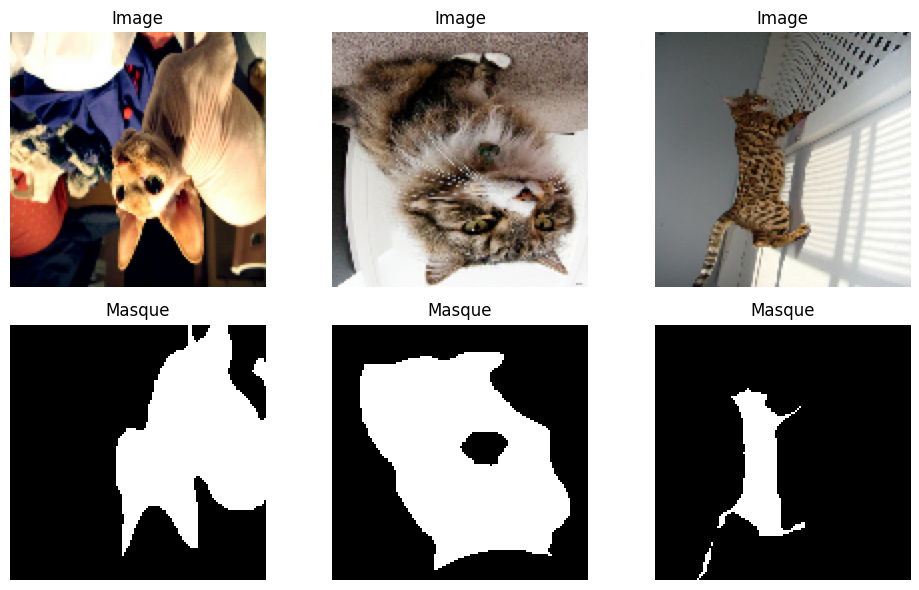

In [8]:
plt.figure(figsize=(10, 6))

for images, masks in train_ds.take(1):
    for i in range(3):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i])
        plt.title("Image")
        plt.axis("off")

        plt.subplot(2, 3, i + 4)
        plt.imshow(tf.squeeze(masks[i]), cmap="gray")
        plt.title("Masque")
        plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
def conv_block(x, filters):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    return x

def encoder_block(x, filters):
    f = conv_block(x, filters)
    p = tf.keras.layers.MaxPooling2D((2, 2))(f)
    return f, p

def decoder_block(x, skip, filters, use_skip=True):
    x = tf.keras.layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    if use_skip:
        x = tf.keras.layers.Concatenate()([x, skip])
    x = conv_block(x, filters)
    return x

In [10]:
def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), use_skip=True):
    inputs = tf.keras.Input(shape=input_shape)

    # Encodeur
    s1, p1 = encoder_block(inputs, 64)
    s2, p2 = encoder_block(p1, 128)
    s3, p3 = encoder_block(p2, 256)
    s4, p4 = encoder_block(p3, 512)

    # Bottleneck
    b1 = conv_block(p4, 1024)

    # Décodeur
    d1 = decoder_block(b1, s4, 512, use_skip=use_skip)
    d2 = decoder_block(d1, s3, 256, use_skip=use_skip)
    d3 = decoder_block(d2, s2, 128, use_skip=use_skip)
    d4 = decoder_block(d3, s1, 64, use_skip=use_skip)

    outputs = tf.keras.layers.Conv2D(1, 1, padding="same", activation="sigmoid")(d4)

    model = tf.keras.Model(inputs, outputs, name="U_Net" if use_skip else "U_Net_no_skip")
    return model

In [11]:
unet_model = build_unet(use_skip=True)
unet_model.summary()

Model: "U_Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 512) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8,      │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  2,097,664 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,031,745 (118.38 MB)

 Trainable params: 31,031,745 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
dummy = tf.random.normal((1, IMG_SIZE, IMG_SIZE, 3))
pred = unet_model(dummy)

print("Entrée :", dummy.shape)
print("Sortie :", pred.shape)

Entrée : (1, 128, 128, 3)
Sortie : (1, 128, 128, 1)


In [13]:
def dice_score(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > 0.5, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)

    return (2.0 * intersection + smooth) / (union + smooth)

def soft_dice_score(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)

    return (2.0 * intersection + smooth) / (union + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - soft_dice_score(y_true, y_pred)

def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return bce + dice_loss(y_true, y_pred)

pixel_accuracy = tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")

In [ ]:
class TimeHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_ti
        mes.append(time.time() - self.start_time)

In [15]:
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=bce_dice_loss,
    metrics=[pixel_accuracy, dice_score]
)

In [16]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

time_callback_unet = TimeHistory()

history_unet = unet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks + [time_callback_unet],
    verbose=1
)

Epoch 1/20
  2/184 ━━━━━━━━━━━━━━━━━━━━ 47:41 16s/step - dice_score: 0.0205 - loss: 1.3077 - pixel_accuracy: 0.6785  

KeyboardInterrupt: 

In [ ]:
test_results_unet = unet_model.evaluate(test_ds, verbose=1)

print("\nRésultats U-Net complète")
for name, value in zip(unet_model.metrics_names, test_results_unet):
    print(f"{name}: {value:.4f}")

print("Temps moyen/époque :", np.mean(time_callback_unet.epoch_times))

In [ ]:
def plot_history(history, title="U-Net"):
    hist = history.history
    epochs = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.plot(epochs, hist["loss"], label="Train loss")
    plt.plot(epochs, hist["val_loss"], label="Val loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 3, 2)
    plt.plot(epochs, hist["pixel_accuracy"], label="Train pixel acc")
    plt.plot(epochs, hist["val_pixel_accuracy"], label="Val pixel acc")
    plt.title(f"{title} - Pixel Accuracy")
    plt.xlabel("Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 3, 3)
    plt.plot(epochs, hist["dice_score"], label="Train Dice")
    plt.plot(epochs, hist["val_dice_score"], label="Val Dice")
    plt.title(f"{title} - Dice Score")
    plt.xlabel("Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_unet, "U-Net complète")

In [ ]:
def display_predictions(model, dataset, num_images=5):
    for images, masks in dataset.take(1):
        preds = model.predict(images)
        preds = (preds > 0.5).astype(np.float32)

        plt.figure(figsize=(12, num_images * 3))

        for i in range(num_images):
            plt.subplot(num_images, 3, 3*i + 1)
            plt.imshow(images[i])
            plt.title("Image")
            plt.axis("off")

            plt.subplot(num_images, 3, 3*i + 2)
            plt.imshow(tf.squeeze(masks[i]), cmap="gray")
            plt.title("Ground truth")
            plt.axis("off")

            plt.subplot(num_images, 3, 3*i + 3)
            plt.imshow(tf.squeeze(preds[i]), cmap="gray")
            plt.title("Prédiction")
            plt.axis("off")

        plt.tight_layout()
        plt.show()

display_predictions(unet_model, test_ds, num_images=5)

In [ ]:
unet_no_skip = build_unet(use_skip=False)
unet_no_skip.summary()

In [ ]:
unet_no_skip.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=bce_dice_loss,
    metrics=[pixel_accuracy, dice_score]
)

In [ ]:
time_callback_no_skip = TimeHistory()

history_unet_no_skip = unet_no_skip.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks + [time_callback_no_skip],
    verbose=1
)

In [ ]:
test_results_unet_no_skip = unet_no_skip.evaluate(test_ds, verbose=1)

print("\nRésultats U-Net sans skip connections")
for name, value in zip(unet_no_skip.metrics_names, test_results_unet_no_skip):
    print(f"{name}: {value:.4f}")

print("Temps moyen/époque :", np.mean(time_callback_no_skip.epoch_times))

In [ ]:
def compare_models_predictions(model1, model2, dataset, num_images=3):
    for images, masks in dataset.take(1):
        preds1 = (model1.predict(images) > 0.5).astype(np.float32)
        preds2 = (model2.predict(images) > 0.5).astype(np.float32)

        plt.figure(figsize=(15, num_images * 3))

        for i in range(num_images):
            plt.subplot(num_images, 4, 4*i + 1)
            plt.imshow(images[i])
            plt.title("Image")
            plt.axis("off")

            plt.subplot(num_images, 4, 4*i + 2)
            plt.imshow(tf.squeeze(masks[i]), cmap="gray")
            plt.title("GT")
            plt.axis("off")

            plt.subplot(num_images, 4, 4*i + 3)
            plt.imshow(tf.squeeze(preds1[i]), cmap="gray")
            plt.title("U-Net complète")
            plt.axis("off")

            plt.subplot(num_images, 4, 4*i + 4)
            plt.imshow(tf.squeeze(preds2[i]), cmap="gray")
            plt.title("Sans skip")
            plt.axis("off")

        plt.tight_layout()
        plt.show()

compare_models_predictions(unet_model, unet_no_skip, test_ds, num_images=3)

In [ ]:
results_c = pd.DataFrame([
    {
        "Variante": "U-Net complet (avec skip)",
        "Dice Score": test_results_unet[2],
        "Acc. pixel": test_results_unet[1],
        "Temps/epoque (s)": np.mean(time_callback_unet.epoch_times)
    },
    {
        "Variante": "U-Net sans skip connections",
        "Dice Score": test_results_unet_no_skip[2],
        "Acc. pixel": test_results_unet_no_skip[1],
        "Temps/epoque (s)": np.mean(time_callback_no_skip.epoch_times)
    }
])

results_c